# Z-Image-Turbo on a free Colab T4 — text-to-image + a public API (+ Qwen turbo for comparison)

Runs **Z-Image-Turbo** (Tongyi-MAI's 6B S3-DiT, Apache-licensed) headless
with stock ComfyUI — no custom nodes needed for it — generates a sample
image, and prints a **public API URL** (Cloudflare quick tunnel — no
account) you can call from any machine. The Qwen-Image turbo GGUF stack is
installed alongside so the head-to-head is reproducible with
`--engine qwen`.

- ⏱ **~15 minutes end to end** (install 1 min → downloads ~6 min for both
  stacks (~36 GB) → boot 2 min → first image ~2 min → tunnel 15 s).
  Everything is measured; see the repo README for the table and the gotchas.
- ⚠️ **Requires the T4 runtime**: menu *Runtime → Change runtime type → T4
  GPU → Save* (free tier), then *Runtime → Run all*. Cell 1 checks and warns.
- ⚡ Settings are the official Z-Image recipe, measured on the free T4:
  **768×768, 8 steps, cfg off** → **~18 s per warm image** — the fastest
  thing measured on a free T4. One catch the README explains: a **new**
  prompt costs one text-encoder reload (~42 s); repeats of the same prompt
  don't.
- ⚖️ Z-Image-Turbo: **Apache-2.0**. The bundled Qwen comparison engine:
  Qwen Research License (check before commercial use).


In [ ]:
# Cell 1 — make sure this runtime actually has a GPU
import subprocess
out = ""
try:
    out = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
        capture_output=True, text=True, timeout=30).stdout.strip()
except Exception:
    pass
if "T4" not in out:
    print("WARNING: expected a T4 GPU, got:", out or "no GPU at all")
    raise SystemExit("Menu: Runtime -> Change runtime type -> T4 GPU -> Save, "
                     "then Runtime -> Run all again.")
print("OK: gpu -", out)


OK: gpu - Tesla T4, 15360 MiB


In [ ]:
# Cell 2 — ComfyUI + the two extras the QWEN engine needs (idempotent).
# Z-Image itself is stock ComfyUI — no custom nodes. The leejet ComfyUI-GGUF
# fork and Viggle's turbo node exist for the --engine qwen comparison mode.
import os, time
t0 = time.time()
if not os.path.isdir("/content/ComfyUI"):
    !git clone --depth 1 https://github.com/comfyanonymous/ComfyUI /content/ComfyUI
    !pip install -q -r /content/ComfyUI/requirements.txt
if not os.path.isdir("/content/ComfyUI/custom_nodes/ComfyUI-GGUF"):
    # the leejet fork, NOT city96 — city96 fails with "Unknown model architecture!"
    !git clone --depth 1 https://github.com/leejet/ComfyUI-GGUF /content/ComfyUI/custom_nodes/ComfyUI-GGUF
    !pip install -q -r /content/ComfyUI/custom_nodes/ComfyUI-GGUF/requirements.txt
if not os.path.exists("/content/ComfyUI/custom_nodes/viggle_turbo.py"):
    !wget -q --tries=3 --timeout=60 https://huggingface.co/Viggle/Qwen-Image-2.1-viggle-turbo/resolve/main/comfyui/viggle_turbo.py -O /content/ComfyUI/custom_nodes/viggle_turbo.py
print(f"OK: install ({time.time() - t0:.0f}s)")


Cloning into '/content/ComfyUI'...


remote: Enumerating objects: 1385, done.
remote: Counting objects: 100% (1385/1385), done.
remote: Compressing objects: 100% (1185/1185), done.


remote: Total 1385 (delta 154), reused 1281 (delta 153), pack-reused 0 (from 0)
Receiving objects: 100% (1385/1385), 12.16 MiB | 16.15 MiB/s, done.
Resolving deltas: 100% (154/154), done.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━ 17.5/25.2 MB 208.7 MB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.2/25.2 MB 85.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 100.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/47.2 MB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━ 42.7/47.2 MB 190.7 MB/s eta 0:00:01

... (48 outputs left out)

Cloning into '/content/ComfyUI/custom_nodes/ComfyUI-GGUF'...


remote: Enumerating objects: 19, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 19 (delta 0), reused 6 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (19/19), 34.62 KiB | 581.00 KiB/s, done.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.5/118.5 kB 6.7 MB/s eta 0:00:00


OK: install (43s)


In [ ]:
# Cell 3 — download both model stacks (idempotent, resumes partial downloads)
import os, shutil, time
ZB = "https://huggingface.co/Comfy-Org/z_image_turbo/resolve/main/split_files"
UNSLOTH = "https://huggingface.co/unsloth/Qwen-Image-2.1-GGUF/resolve/main"
ABENZ = "https://huggingface.co/abenzerps/Qwen-Image-2.1-GGUF/resolve/main"
VIGGLE = "https://huggingface.co/Viggle/Qwen-Image-2.1-viggle-turbo/resolve/main"
FILES = [
    # Z-Image stack (Comfy-Org split files; the official t2i template's picks)
    (f"{ZB}/diffusion_models/z_image_turbo_bf16.safetensors",
     "/content/ComfyUI/models/diffusion_models/z_image_turbo_bf16.safetensors"),
    (f"{ZB}/text_encoders/qwen_3_4b.safetensors",
     "/content/ComfyUI/models/text_encoders/qwen_3_4b.safetensors"),
    (f"{ZB}/vae/ae.safetensors",
     "/content/ComfyUI/models/vae/ae.safetensors"),
    # Qwen comparison stack
    (f"{UNSLOTH}/qwen-image-2.1-Q4_K_M.gguf",
     "/content/ComfyUI/models/diffusion_models/qwen-image-2.1-Q4_K_M.gguf"),
    (f"{ABENZ}/text_encoders/qwen3vl_8b_int8_convrot.safetensors",
     "/content/ComfyUI/models/text_encoders/qwen3vl_8b_int8_convrot.safetensors"),
    (f"{ABENZ}/vae/qwen_image_2.1_vae_bf16.safetensors",
     "/content/ComfyUI/models/vae/qwen_image_2.1_vae_bf16.safetensors"),
    (f"{VIGGLE}/Qwen-Image-2.1-viggle-turbo-v0.2.1-6step-lora-r256.safetensors",
     "/content/ComfyUI/models/loras/Qwen-Image-2.1-viggle-turbo-v0.2.1-6step-lora-r256.safetensors"),
]
t0 = time.time()
for url, dest in FILES:
    if os.path.exists(dest) and os.path.getsize(dest) > 1e8:
        print("cached:", os.path.basename(dest))
        continue
    print("downloading:", os.path.basename(dest))
    !wget -q -c --tries=3 --timeout=60 {url} -O {dest}
    assert os.path.getsize(dest) > 1e8, (
        f"download failed: {dest} — delete the partial file and re-run this cell")
# loader-compat copies for the Qwen GGUF path (some node versions scan unet/ and clip/)
os.makedirs("/content/ComfyUI/models/unet", exist_ok=True)
shutil.copy(FILES[3][1], "/content/ComfyUI/models/unet/")
os.makedirs("/content/ComfyUI/models/clip", exist_ok=True)
shutil.copy(FILES[4][1], "/content/ComfyUI/models/clip/")
print(f"OK: download ({time.time() - t0:.0f}s total, ~36 GB fresh)")


downloading: z_image_turbo_bf16.safetensors


downloading: qwen_3_4b.safetensors


downloading: ae.safetensors


downloading: qwen-image-2.1-Q4_K_M.gguf


downloading: qwen3vl_8b_int8_convrot.safetensors


downloading: qwen_image_2.1_vae_bf16.safetensors


downloading: Qwen-Image-2.1-viggle-turbo-v0.2.1-6step-lora-r256.safetensors


OK: download (377s total, ~36 GB fresh)


In [ ]:
# Cell 4 — boot ComfyUI headless with the measured T4 flags (idempotent)
import subprocess, sys, time, urllib.request
BASE = "http://127.0.0.1:8188"
def alive():
    try:
        urllib.request.urlopen(BASE + "/system_stats", timeout=5)
        return True
    except Exception:
        return False
if alive():
    print("OK: launch (server already running — skipping boot)")
else:
    # --force-fp16: T4 has no bf16, so default cast is fp32 (much slower).
    # --disable-comfy-compiler: required with fp16 on the T4, else the first
    #   forward dies with "aimdo memory compile error" (ComfyUI model compiler).
    FLAGS = ["--force-fp16", "--disable-comfy-compiler"]
    log = open("/content/comfyui.log", "w")
    proc = subprocess.Popen(
        [sys.executable, "main.py", "--listen", "127.0.0.1", "--port", "8188", *FLAGS],
        cwd="/content/ComfyUI", stdout=log, stderr=subprocess.STDOUT)
    t0 = time.time()
    while not alive():
        if proc.poll() is not None or time.time() - t0 > 300:
            print(open("/content/comfyui.log").read()[-2000:])
            raise SystemExit("ComfyUI failed to boot - log tail above. "
                             "See the repo's troubleshooting guide.")
        time.sleep(3)
    print(f"OK: launch ({time.time() - t0:.0f}s)")


OK: launch (27s)


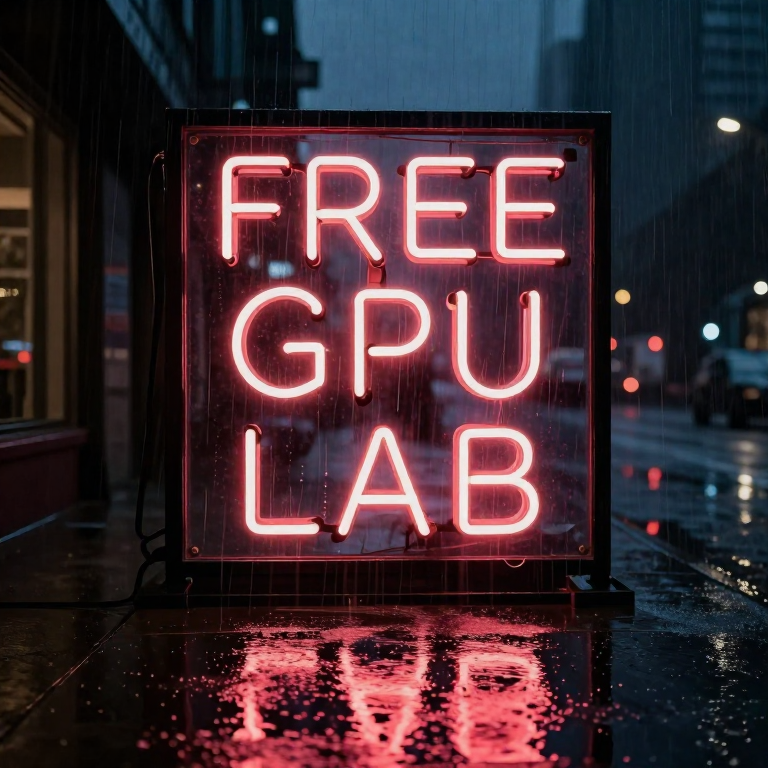

OK: generate (105s incl. first-time model loads; warm repeats of a prompt run ~18 s, a NEW prompt ~42 s) -> /content/z-sample.png


In [ ]:
# Cell 5 — verify the graph nodes exist, then generate the Z-Image sample
import json, time, urllib.parse, urllib.request
from IPython.display import Image as IPyImage, display
BASE = "http://127.0.0.1:8188"
def api(path, payload=None, timeout=60):
    if payload is None:
        req = urllib.request.Request(BASE + path)
    else:
        req = urllib.request.Request(BASE + path, data=json.dumps(payload).encode(),
                                     method="POST",
                                     headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return json.loads(r.read())

oi = api("/object_info")
assert "UNETLoader" in oi and "ModelSamplingAuraFlow" in oi, (
    "stock ComfyUI Z-Image nodes missing - update ComfyUI (git pull)")
clip_types = (oi["CLIPLoader"]["input"].get("required", {}).get("type")
              or oi["CLIPLoader"]["input"].get("optional", {}).get("type"))
assert "lumina2" in clip_types[0], "CLIPLoader lacks the lumina2 type - update ComfyUI"
assert "UnetLoaderGGUF" in oi and "ViggleTurboLora" in oi, (
    "Qwen comparison stack missing - re-run cell 2, then Restart runtime "
    "(custom nodes load at server boot)")

# The official Z-Image recipe, measured on the free T4: 768x768, 8 steps,
# cfg off, lumina2 clip + ModelSamplingAuraFlow shift=3. ~18 s warm repeat.
wf = {
    "1": {"class_type": "UNETLoader",
          "inputs": {"unet_name": "z_image_turbo_bf16.safetensors",
                     "weight_dtype": "default"}},
    "2": {"class_type": "CLIPLoader",
          "inputs": {"clip_name": "qwen_3_4b.safetensors",
                     "type": "lumina2", "device": "default"}},
    "3": {"class_type": "VAELoader",
          "inputs": {"vae_name": "ae.safetensors"}},
    "4": {"class_type": "CLIPTextEncode",
          "inputs": {"clip": ["2", 0],
                     "text": 'a neon shop sign that reads "FREE GPU LAB", rainy night, reflections on wet pavement'}},
    "5": {"class_type": "ConditioningZeroOut",
          "inputs": {"conditioning": ["4", 0]}},
    "6": {"class_type": "EmptySD3LatentImage",
          "inputs": {"width": 768, "height": 768, "batch_size": 1}},
    "7": {"class_type": "ModelSamplingAuraFlow",
          "inputs": {"model": ["1", 0], "shift": 3}},
    "8": {"class_type": "KSampler",
          "inputs": {"model": ["7", 0], "positive": ["4", 0],
                     "negative": ["5", 0], "latent_image": ["6", 0],
                     "seed": 42, "steps": 8, "cfg": 1.0,
                     "sampler_name": "res_multistep",
                     "scheduler": "simple", "denoise": 1.0}},
    "9": {"class_type": "VAEDecode",
          "inputs": {"samples": ["8", 0], "vae": ["3", 0]}},
    "10": {"class_type": "SaveImage",
           "inputs": {"images": ["9", 0], "filename_prefix": "z_t4_sample"}},
}
pid = api("/prompt", {"prompt": wf, "client_id": "notebook"})["prompt_id"]
t0 = time.time()
imgs = []
while time.time() - t0 < 1500:
    time.sleep(3)
    hist = api(f"/history/{pid}", timeout=20)
    if pid not in hist:
        continue
    entry = hist[pid]
    if entry.get("status", {}).get("status_str") == "error":
        print(json.dumps(entry["status"].get("messages", []))[:800])
        raise SystemExit("generation failed - see the repo's troubleshooting guide")
    imgs = [im for out in entry.get("outputs", {}).values() for im in out.get("images", [])]
    if imgs:
        break
assert imgs, "timeout waiting for the image"
q = urllib.parse.urlencode({"filename": imgs[0]["filename"],
                            "subfolder": imgs[0].get("subfolder", ""),
                            "type": imgs[0].get("type", "output")})
data = urllib.request.urlopen(f"{BASE}/view?{q}", timeout=120).read()
open("/content/z-sample.png", "wb").write(data)
display(IPyImage("/content/z-sample.png"))
print(f'OK: generate ({time.time() - t0:.0f}s incl. first-time model loads; '
      f'warm repeats of a prompt run ~18 s, a NEW prompt ~42 s) -> /content/z-sample.png')


In [ ]:
# Cell 6 — expose the API through a public quick tunnel (no account needed)
import os, re, subprocess, time
CF = "/content/cloudflared"
if not os.path.exists(CF):
    !wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O {CF}
    !chmod +x {CF}
subprocess.run(["pkill", "-f", "cloudflared tunnel"], check=False)  # fresh URL on re-run
time.sleep(1)
tun_log = open("/content/cloudflared.log", "w")
subprocess.Popen([CF, "tunnel", "--url", "http://localhost:8188", "--no-autoupdate"],
                 stdout=tun_log, stderr=subprocess.STDOUT)
url = None
t0 = time.time()
while url is None and time.time() - t0 < 60:
    time.sleep(2)
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com",
                  open("/content/cloudflared.log").read())
    url = m.group(0) if m else None
assert url, "tunnel failed - see /content/cloudflared.log"
print("API URL:", url)
print("OK: tunnel")


API URL: https://ideas-medications-britannica-filme.trycloudflare.com
OK: tunnel


In [ ]:
# Cell 7 — copy-paste usage with YOUR tunnel URL filled in
print(f"""
Your text-to-image API is live from anywhere (while this notebook runs):

  python3 txt2img.py --url {url} \\
      --prompt 'a red fox in snow, film photo' --out fox.png

Default engine: Z-Image turbo (8 steps, CFG off) — fastest on repeats of a
prompt (~18 s warm); a NEW prompt pays one text-encoder reload (~42 s).
Switch to the bundled Qwen comparison engine — steady ~27 s on any prompt:

  python3 txt2img.py --url {url} --engine qwen \\
      --prompt 'a red fox in snow, film photo' --out fox-qwen.png

(txt2img.py ships in the repo under clients/ - it needs only Python 3,
no installs. The URL changes every notebook re-run.)

Raw HTTP works too:
  curl {url}/system_stats
""")
print("OK: api")



Your text-to-image API is live from anywhere (while this notebook runs):

  python3 txt2img.py --url https://ideas-medications-britannica-filme.trycloudflare.com \
      --prompt 'a red fox in snow, film photo' --out fox.png

Default engine: Z-Image turbo (8 steps, CFG off) — fastest on repeats of a
prompt (~18 s warm); a NEW prompt pays one text-encoder reload (~42 s).
Switch to the bundled Qwen comparison engine — steady ~27 s on any prompt:

  python3 txt2img.py --url https://ideas-medications-britannica-filme.trycloudflare.com --engine qwen \
      --prompt 'a red fox in snow, film photo' --out fox-qwen.png

(txt2img.py ships in the repo under clients/ - it needs only Python 3,
no installs. The URL changes every notebook re-run.)

Raw HTTP works too:
  curl https://ideas-medications-britannica-filme.trycloudflare.com/system_stats

OK: api


## The measured head-to-head (free T4, same canary + seed, full table in the README)

| Row (768×768) | Z-Image bf16 (this notebook) | Qwen turbo (`--engine qwen`) |
|---|---|---|
| warm repeat of a prompt | **18.0 s** | 27.0 s |
| first render with a NEW prompt | 42.0 s | 30.0 s |
| warm at 1024×1024 | 39.0 s | 42.0 s |
| session's first image (load included) | 102.1 s | 84.1 s |

**Workload rule:** batches of variations on one prompt → Z-Image; mixed
prompts / interactive → Qwen.

## Tweaking cheat sheet (all measured on this exact setup)

| Change | Effect |
|---|---|
| `--engine qwen` | the bundled Qwen turbo GGUF engine (see table above) |
| `width/height: 768` → 1024 | Z-Image's training size, best quality: 39.0 s warm |
| the int8 split (`z_image_turbo_int8_convrot`) | 6.2 GB instead of 12.3 GB, same quality, **slower** on T4: ~4.1 s/step vs 1.8 (60.0 s warm incl. swap) |
| Z-Image nvfp4 split | do NOT bother on T4 — nvfp4 wants Blackwell-era hardware |
| sampler / scheduler | keep `res_multistep`/`simple` + AuraFlow shift 3 — that IS the official recipe |
| qwen small dense text | the 8-step schedule documented in the sibling repo |

Gotchas that will bite if forgotten (full list in
`references/05-troubleshooting.md`):

- The T4 needs BOTH `--force-fp16` and `--disable-comfy-compiler` (cell 4).
- Z-Image's text encoder loads as **`type: lumina2`** in CLIPLoader — there
  is no z_image type (the encoder is a Qwen3-4B; this is the official
  template's wiring).
- `ModelSamplingAuraFlow shift=3` is part of the recipe, not a stylistic
  choice — the official template ships it.
- The 12.3 GB Z-Image unet + 8 GB text encoder cannot both stay resident on
  a 15.6 GB T4, so expect the per-new-prompt reload. It is the price of the
  full-precision model; the int8 split avoids it but runs slower per step.
- The tunnel URL is new on every run; the VM sleeps when idle.

When finished: *Runtime → Manage sessions → TERMINATE* — free GPU minutes are
a shared budget.
